# Модель для предсказания массы морских черепах

Выполнил: Серов Константин

Дата: 22.08.2026

**Задача:** разработать надёжную модель линейной регрессии, которая будет использовать габариты и другие данные от TurtleCV для предсказания массы черепах.

## Постановка задачи машинного обучения

- **Задача.** Наша модель должна предсказывать массу черепахи - непрерывную величину, поэтому нам предстоит решать задачу регрессии.
- **Целевая переменная.** Целевой переменной нашей модели станет масса черепахи (поле `weight`), так как именно её наша модель должна будет определять.
- **Метрики качества модели.** Для оценки качества модели будем использовать несколько метрик. Основная — MAE, так как она напрямую показывает среднюю ошибку в килограммах и заказчик задал по ней чёткий критерий (не более 5 кг для взрослых особей). Дополнительно рассчитаем MAPE — она покажет относительную ошибку и позволит корректно сравнивать качество предсказаний для черепах разного размера. Также будем отслеживать R² — долю объяснённой дисперсии массы, критерий заказчика: не менее 0.97. MSE используем как вспомогательную метрику при сравнении моделей между собой.
- **Критерии успешности проекта с опорой на метрики.** Проект будем считать успешным, если итоговая модель — линейная регрессия покажет на валидационной и тестовой выборках следующие результаты:
  - MAE не более 5 кг для взрослых особей (масса 50-150 кг);
  - R² не менее 0.97;
  - стабильность метрик между валидацией и тестом — отсутствие признаков переобучения (существенного расхождения показателей).

## Подключение и настройка библиотек

Импортируем необходимые библиотеки.

In [1]:
import numpy as np
import pandas as pd

# Визуализация
import matplotlib.pyplot as plt
import seaborn as sns

# Разбиение данных
from sklearn.model_selection import train_test_split

# Модели линейной регрессии
from sklearn.linear_model import LinearRegression, Ridge, Lasso, SGDRegressor

# Метрики
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score

## Загрузка датасета

- Загрузим данные из файла `turtles.csv`, путь к файлу: `'/datasets/turtles.csv'`. При использовании метода [read_csv](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.read_csv.html) установите правильные значения для параметров `sep` и `decimal`: в качестве разделителя столбцов используйте символ табуляции (`'\t'`), а в качестве разделителя дробной части — запятую.

In [2]:
# Запишем данные из turtles.csv в датафрейм df
df = pd.read_csv('/datasets/turtles.csv', sep = '\t', decimal = ',')

Познакомимся с данными сформированного датасета - выведем первые строки методом `head()`, а информацию о датафрейме методом `info()`:

In [3]:
# Вывод первых строк датафрейма
df.head(10)

,id,binomial_name,registration number,shell_length,shell_width,head_length,head_width,flipper_length_1,flipper_width_1,flipper_length_2,flipper_width_2,flipper_length_3,flipper_width_3,flipper_length_4,flipper_width_4,circle_count,measure_count,shell_crack,timestamp,weight
0,20438,Caretta caretta,d89af72662f49ece4d09dec75a8b0166,700.0,381,112.0,82.0,356,205,331,185,270.0,180.0,273.0,144.0,63,3.0,NaN,1703159226,87.687
1,19034,Lepidochelys olivacea,1579c64777de4db1c16e8b7b0d19c45e,341.0,295,65.0,48.0,216,190,229,186,164.0,182.0,180.0,149.0,0,1.0,1.0,1689428175,26.949
2,24689,LEPIDOCHELYS OLIVACEA,bfcec01187569615087e4d777c44985a,408.0,343,71.0,70.0,308,224,285,232,264.0,179.0,268.0,176.0,0,3.0,NaN,1745783111,30.016
3,17945,Lepidochelys Olivacea,2c159675aa28f0ea566fce2090bf4c82,512.0,432,98.0,95.0,334,317,364,284,NaN,NaN,NaN,NaN,3,4.0,1.0,1677757151,33.917
4,24543,lepidochelys olivacea,ecd22499761e2ac56a6d8eb765ec566d,408.0,307,50.0,54.0,280,168,269,218,199.0,165.0,209.0,180.0,0,4.0,1.0,1744455613,28.511
5,25045,Lepidochelys olivacea,1b076bdf8f9ed92f370f64ffd28b7dd6,341.0,254,54.0,55.0,250,204,240,217,197.0,152.0,185.0,154.0,0,1.0,NaN,1749366080,27.513
6,23228,Lepidochelys olivacea,ad587cf0ebf5ac3a337fc55f91b16086,606.0,526,114.0,91.0,489,407,460,316,440.0,260.0,326.0,300.0,32,2.0,NaN,1731882409,40.228
7,19458,Lepidochelys olivacea,a9d0a18fc14b993b95ea02a314aa4aee,600.0,551,104.0,109.0,411,328,396,338,356.0,258.0,321.0,266.0,20,3.0,NaN,1693572979,38.838
8,25241,Chelonia mydas,0d05dca974d9f624d9c9f8e38817f827,742.0,652,118.0,147.0,411,386,507,389,414.0,368.0,311.0,325.0,66,4.0,1.0,1751228603,56.352
9,20199,Lepidochelys olivacea,baa40598df8e5120e81c65a847a5a5be,399.0,336,NaN,NaN,264,240,288,234,215.0,161.0,226.0,186.0,0,4.0,NaN,1700915750,29.823


In [4]:
# Общая информация строк датафрейма
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8861 entries, 0 to 8860
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   8861 non-null   int64  
 1   binomial_name        8812 non-null   object 
 2   registration number  8832 non-null   object 
 3   shell_length         8774 non-null   float64
 4   shell_width          8861 non-null   int64  
 5   head_length          8715 non-null   float64
 6   head_width           8715 non-null   float64
 7   flipper_length_1     8861 non-null   int64  
 8   flipper_width_1      8861 non-null   int64  
 9   flipper_length_2     8861 non-null   int64  
 10  flipper_width_2      8861 non-null   int64  
 11  flipper_length_3     8760 non-null   float64
 12  flipper_width_3      8760 non-null   float64
 13  flipper_length_4     8760 non-null   float64
 14  flipper_width_4      8760 non-null   float64
 15  circle_count         8861 non-null   i

Датасет содержит 20 столбцов и 8861 строку, в которых представлена информация о габаритах и других данные от портативной системы компьютерного зрения TurtleCV.

Среди представленныъ данных 10 столбцов содержат значения типа `float`, 8 столбцов - тип `int` и 2 столбца со значениями типа `object`.

**Изучим типы данных и их корректность**
- **Целочисленный тип (`int64`):**
  - `id` - идентификатор измерения. Тип корректен, можно оптимизировать размерность. Вероятно, этот признак будет исключён, так как не содержит полезной информации для обучения модели.
  - `shell_width` - ширина панциря, мм. Тип корректен. Также можно оптимизировать размерность.
  - `flipper_length_1` - длина ласты номер 1, мм. У черепах четыре ласты, поэтому в датасете четыре таких столбца, в названиях указан номер от 1 до 4. Тип корректен, можно оптимизировать размерность.
  - `flipper_width_1` - ширина ласты номер 1, мм. Тип корректен, можно оптимизировать размерность.
  - `flipper_length_2` - длина ласты номер 2, мм. Тип корректен, можно оптимизировать размерность.
  - `flipper_width_2` - ширина ласты номер 2, мм. Тип корректен, можно оптимизировать размерность.
  - `circle_count` - количество колец роста на панцире черепахи. Тип корректен, можно оптимизировать размерность.
  - `timestamp` - время внесения данных о черепахе. Тип `int`, скорее всего, означает, что это Unix-время. Корректнее было бы привести эти данные к типу `timestamp`, однако, этот признак может не понадобиться для обучения модели. 
- **Тип с плавающей точкой (`float64`):**
  - `shell_length` - длина панциря, мм. В целом тип корректен. Однако видно, что в этом столбце содержатся пропуски (8861 - 8774 = 87 пропусков). `NaN` — это `float`, поэтому pandas принудительно приводит весь столбец к `float64`, даже если по смыслу там должны быть целые числа. После обработки пропусков столбец стоит привести к типу `int`, если столбец не содержит значений с дробной частью.
  - `head_length` - длина головы, мм. Аналогично с `shell_length`. После обработки пропусков (8861 - 8715 = 146 пропусков) столбец стоит привести к типу `int`, если столбец не содержит значений с дробной частью.
  - `head_width` - ширина головы, мм. Аналогично с `shell_length`. После обработки пропусков (8861 - 8715 = 146 пропусков) столбец стоит привести к типу `int`, если столбец не содержит значений с дробной частью.
  - `flipper_length_3` - длина ласты номер 3, мм. Аналогично с `shell_length`. После обработки пропусков (8861 - 8760 = 101 пропусков) столбец стоит привести к типу `int`, если столбец не содержит значений с дробной частью.
  - `flipper_width_3` - ширина ласты номер 3, мм. Аналогично с `shell_length`. После обработки пропусков (8861 - 8760 = 101 пропусков) столбец стоит привести к типу `int`, если столбец не содержит значений с дробной частью.
  - `flipper_length_4` - длина ласты номер 4, мм. Аналогично с `shell_length`. После обработки пропусков (8861 - 8760 = 101 пропусков) столбец стоит привести к типу `int`, если столбец не содержит значений с дробной частью.
  - `flipper_width_4` - ширина ласты номер 4, мм. Аналогично с `shell_length`. После обработки пропусков (8861 - 8760 = 101 пропусков) столбец стоит привести к типу `int`, если столбец не содержит значений с дробной частью.
  - `measure_count` - количество измерений по модели компьютерного зрения перед усреднением показателей. Такие данные несут целочисленный характер. Вероятно, причина в пропусках (8861 - 8597 = 264), `NaN` — это `float`. После обработки пропусков столбец стоит привести к типу `int`.
  - `shell_crack` - наличие трещин панциря. `NaN` — это `float`. Наблюдается большое количество пропусков (8861 - 2176 = 6685 пропусков). Гипотеза: большая часть этих `NaN` означает именно отсутствие трещин, а не самих данных. Этот столбец стоит привести к типу `bool`, где 1 - трещины есть, 0 - трещин нет.
  - `weight` - масса черепахи, кг. Целевой параметр нашей модели. Столбце содержит небольшое количество пропусков (8861 - 8842 = 19). Тип данных корректен. Также можно оптимизировать размерность.
- **Объектовый тип (`object`):**
  - `binomial_name` - международное научное название вида черепахи. Тип корректен. Имеются пропуски (8861 - 8812 = 49 пропусков).
  - `registration number` - регистрационный номер черепахи. Тип корректен. Кандидат на исключение. Имеются пропуски (8861 - 8832 = 29 пропусков). В имени столбца имеется отклонение от snake_case регистра, применяемого во всех других названиях столбцов датафрейма. Название этого столбца также стоит привести к регистру snake_case.
  
Датасет содержит 20 признаков с корректными в целом типами данных: 8 целочисленных, 10 вещественных и 2 категориальных (`object`). Большинство `float`-столбцов получили этот тип не из-за дробной природы значений, а из-за пропусков (`NaN`), поэтому после их обработки часть признаков (габариты панциря, головы, ласт) потенциально можно будет привести к `int` — это предстоит проверить отдельно. Также выявлены кандидаты на исключение из модели (`id`, `timestamp`, `registration number`) и признаки, требующие особого подхода при заполнении пропусков (`shell_crack`) и преобразовании типа (`shell_crack` -> `bool`). Имя столбца `registration number` стоит привести к snake_case регистру.

---

## Исследовательский анализ данных

Перед предобработкой данных датафрейма сделаем его копию:

In [5]:
df_preprocessed = df.copy()

Приведём имя столбца `registration number` к snake_case регистру:

In [6]:
df = df.rename(columns={'registration number': 'registration_number'})

In [7]:
df[['registration_number']].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8861 entries, 0 to 8860
Data columns (total 1 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   registration_number  8832 non-null   object
dtypes: object(1)
memory usage: 69.4+ KB


---

### Изучим датасет.
Выясним, данные о каких черепахах представлены в датасете.

Выведем уникальные значения поля `binomial_name`:

In [8]:
# Уникальные виды черепах в датасете
df['binomial_name'].unique()

array(['Caretta caretta', 'Lepidochelys olivacea',
       'LEPIDOCHELYS OLIVACEA', 'Lepidochelys Olivacea',
       'lepidochelys olivacea', 'Chelonia mydas',
       'ERETMOCHELYS IMBRICATA', 'Eretmochelys imbricata',
       'Dermochelys coriacea', 'caretta caretta', 'CARETTA CARETTA',
       'chelonia mydas', 'Chelonia Mydas', 'CHELONIA MYDAS',
       'Dermochelys Coriacea', 'eretmochelys imbricata', nan,
       'Caretta Caretta', 'lepidochelys kempii', 'Lepidochelys kempii',
       'Eretmochelys Imbricata', 'dermochelys coriacea',
       'Lepidochelys Kempii', 'DERMOCHELYS CORIACEA'], dtype=object)

In [9]:
# Количество данных каждого уникального вида
df['binomial_name'].value_counts(dropna=False)

Lepidochelys olivacea     3372
Chelonia mydas            2325
Caretta caretta            674
lepidochelys olivacea      416
Dermochelys coriacea       399
Eretmochelys imbricata     332
Lepidochelys Olivacea      285
chelonia mydas             252
Chelonia Mydas             177
LEPIDOCHELYS OLIVACEA      142
caretta caretta             90
CHELONIA MYDAS              75
NaN                         49
Caretta Caretta             46
eretmochelys imbricata      41
dermochelys coriacea        40
CARETTA CARETTA             37
Eretmochelys Imbricata      28
Dermochelys Coriacea        27
Lepidochelys kempii         22
DERMOCHELYS CORIACEA        18
ERETMOCHELYS IMBRICATA       8
Lepidochelys Kempii          3
lepidochelys kempii          3
Name: binomial_name, dtype: int64

Сразу заметно наличие неявных дубликатов (например, 'Lepidochelys olivacea', 'LEPIDOCHELYS OLIVACEA', 'Lepidochelys Olivacea', 'lepidochelys olivacea'). 

**Нужна обработка от дубликатов.** Приведём все названия к нижнему регистру:

In [10]:
# Количество уникальных значений + NaN до обработки
uniq_befor = df['binomial_name'].nunique() + 1
uniq_befor

24

In [11]:
# Приводим названия видов к единому нижнему регистру
df['binomial_name'] = df['binomial_name'].str.lower()

Повторно выведем уникальные значения поля `binomial_name`:

In [12]:
# Уникальные виды черепах в датасете
df['binomial_name'].unique()

array(['caretta caretta', 'lepidochelys olivacea', 'chelonia mydas',
       'eretmochelys imbricata', 'dermochelys coriacea', nan,
       'lepidochelys kempii'], dtype=object)

In [13]:
# Количество данных каждого уникального вида
df['binomial_name'].value_counts(dropna=False)

lepidochelys olivacea     4215
chelonia mydas            2829
caretta caretta            847
dermochelys coriacea       484
eretmochelys imbricata     409
NaN                         49
lepidochelys kempii         28
Name: binomial_name, dtype: int64

In [14]:
# Количество уникальных значений + NaN после обработки
uniq_after = df['binomial_name'].nunique() + 1
uniq_after

7

**Неявные дубликаты были исключены.** Количество уникальных значений столбца `binomial_name` сократилось с 24 до 7 (включая `NaN`). Было исключено 24 - 7 = 17 дубликатов.

---

### Отбор записей. 
Проведём отбор записей о нужном виде черепах.

Для дальнейшей работы достаточно изучить только *Chelonia mydas*. При этом мы можем сравнить распределение данных об этих черепахах с другими видами.

In [15]:
# Отбираем записи только по виду Chelonia mydas
df_mydas = df[df['binomial_name'] == 'chelonia mydas'].copy()

In [16]:
df_mydas.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 2829 entries, 8 to 8859
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   2829 non-null   int64  
 1   binomial_name        2829 non-null   object 
 2   registration_number  2825 non-null   object 
 3   shell_length         2794 non-null   float64
 4   shell_width          2829 non-null   int64  
 5   head_length          2790 non-null   float64
 6   head_width           2790 non-null   float64
 7   flipper_length_1     2829 non-null   int64  
 8   flipper_width_1      2829 non-null   int64  
 9   flipper_length_2     2829 non-null   int64  
 10  flipper_width_2      2829 non-null   int64  
 11  flipper_length_3     2798 non-null   float64
 12  flipper_width_3      2798 non-null   float64
 13  flipper_length_4     2798 non-null   float64
 14  flipper_width_4      2798 non-null   float64
 15  circle_count         2829 non-null   i

---

### Отбор признаков
Определим, все ли признаки можно использовать для решения задачи. 

В ходе знакомства с данными у нас появились признаки-кандидаты на исключение: `id`, `timestamp`, `registration number`. А также `binomial_name`.
- `id` - уникальный идентификатор измерения, такие признаки могут дать ложную корреляцию и переобучение;
- `timestamp` - момент внесения данных не должен физически влиять на массу;
- `registration number` - тоже идентификатор (черепахи), не несёт физического смысла для массы;
- После фильтрации по 'Chelonia mydas' у всех строк признака `binomial_name` одно и то же значение. Признак с нулевой дисперсией, бесполезен для модели.

Удалим ненужные признаки. Но перед этим сделаем копию датафрейма.

In [17]:
# Копия датафрейма перед удалением лишних признаков
df_befor_delete = df_mydas.copy()

In [18]:
# Удаляем столбцы лишних признаков из датафрейма
df_mydas = df_mydas.drop(columns=['id', 'timestamp', 'registration_number', 'binomial_name'])

Выведем общую информацию об обновлённом датафрейме:

In [19]:
df_mydas.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 2829 entries, 8 to 8859
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   shell_length      2794 non-null   float64
 1   shell_width       2829 non-null   int64  
 2   head_length       2790 non-null   float64
 3   head_width        2790 non-null   float64
 4   flipper_length_1  2829 non-null   int64  
 5   flipper_width_1   2829 non-null   int64  
 6   flipper_length_2  2829 non-null   int64  
 7   flipper_width_2   2829 non-null   int64  
 8   flipper_length_3  2798 non-null   float64
 9   flipper_width_3   2798 non-null   float64
 10  flipper_length_4  2798 non-null   float64
 11  flipper_width_4   2798 non-null   float64
 12  circle_count      2829 non-null   int64  
 13  measure_count     2748 non-null   float64
 14  shell_crack       677 non-null    float64
 15  weight            2826 non-null   float64
dtypes: float64(10), int64(6)
memory usage: 375

Осталось 15 признаков (габариты панциря/головы/ласт, `circle_count`, `measure_count`, `shell_crack`) потенциально информативны + целевая переменная `weight`. Окончательное решение по некоторым из них можно будет уточнить позже, после анализа корреляций.

---

### Пропуски
Проверим, есть ли в данных пропуски. 

Определим, какие из них можно обработать сразу, а в каких случаях лучше сперва провести разделение на выборки. Решим, стоит ли удалить некоторые пропуски.

Явно посчитаем пропуски:

In [20]:
# Считаем количество и долю пропусков по каждому признаку
missing = df_mydas.isna().sum()
missing_shape = (missing / len(df_mydas) * 100).round(2)

pd.DataFrame({'missing_count': missing, 'missing_shape': missing_shape}).sort_values('missing_count', ascending=False)

,missing_count,missing_shape
shell_crack,2152,76.07
measure_count,81,2.86
head_length,39,1.38
head_width,39,1.38
shell_length,35,1.24
flipper_length_3,31,1.10
flipper_width_3,31,1.10
flipper_length_4,31,1.10
flipper_width_4,31,1.10
weight,3,0.11


- Самое большое количество пропусков всё также наблюдается в столбце `shell_crack` - 2152 пропуска (76.1%). У нас была гипотеза, что эти пропуски означают именно отсутствие трещин, а не самих данных.

Посмотрим на количество уникальных значений признака:

In [21]:
df_mydas['shell_crack'].value_counts(dropna=False)

NaN    2152
1.0     440
2.0      89
3.0      67
5.0      56
4.0      25
Name: shell_crack, dtype: int64

Признак `shell_crack`, вероятно, фиксирует количество трещин панциря. Среди заполненных значений отсутствует 0, что говорит в пользу гипотезы: пропуск вносился, когда трещин не было, а не когда их не измеряли. Заполним NaN значением 0, приняв это допущение.

In [22]:
# Заполняем пропуски в shell_crack нулём — гипотеза: NaN = трещин нет
df_mydas['shell_crack'] = df_mydas['shell_crack'].fillna(0)

In [23]:
df_mydas['shell_crack'].value_counts(dropna=False)

0.0    2152
1.0     440
2.0      89
3.0      67
5.0      56
4.0      25
Name: shell_crack, dtype: int64

- Целевая переменная `weight` содержит 3 пропуска. Восстановить её статистически (например, средним) нельзя — это исказит обучение модели, ведь мы будем предсказывать выдуманные значения как настоящие. Строки без известной массы бесполезны для обучения, поэтому удалим их сразу.

In [24]:
# Удаляем строки с пропущенной целевой переменной
df_mydas = df_mydas.dropna(subset=['weight'])
df_mydas.shape

(2826, 16)

До удаления пустых строк целевого признака `weight` в датафрейме `df_mydas` было 2829 строк, стало 2826. Удалили 3 строки - всё верно.

- В случае оставшихся признаков (`measure_count`, `head_length`, `head_width`, `shell_length`, `flipper_length_3`, `flipper_width_3`, `flipper_length_4`, `flipper_width_4`), где количество пропусков варируется от 3 до 1 процентов, лучше сперва провести разделение на выборки, чтобы не допустить утечку данных при заполнении медианой/средним.

В датасете `df_mydas` обнаружены пропуски в 8 признаках: от единичных (1–3%) в габаритах панциря, головы и ласт до критичных 76% в `shell_crack` и 3 пропусков в целевой переменной `weight`. Пропуски в `shell_crack` заполнены нулём по гипотезе "NaN = трещин нет", а строки с пропущенным `weight` удалены, так как целевую переменную нельзя восстанавливать статистически; оба решения не требуют разделения на выборки, поэтому выполнены сразу. Оставшиеся пропуски в габаритных признаках и `measure_count` (1–3%) отложены до "после train/val/test split", чтобы заполнение медианой/средним не привело к утечке данных из val/test в обучение.

---

### Дубликаты
Определим, есть ли в данных дубликаты. 

Выберем корректный способ их обработки.

**Явные дубликаты**

Проверим на полностью совпадающие строки по всем оставшимся столбцам:

In [25]:
# Проверяем явные дубликаты
df_mydas.duplicated().sum()

340

340 явных дубликатов, это довольно большая часть датасета `df_mydas`, около 12%. Стоит глянуть на сами повторяющиеся строки,чтобы понять, действительно ли это "мусор". Посмотрим примеры дублирующихся строк:

In [26]:
# Выведем некоторые дублирующиеся строки
df_mydas[df_mydas.duplicated(keep=False)].sort_values(by=df_mydas.columns.tolist()).head(10)

,shell_length,shell_width,head_length,head_width,flipper_length_1,flipper_width_1,flipper_length_2,flipper_width_2,flipper_length_3,flipper_width_3,flipper_length_4,flipper_width_4,circle_count,measure_count,shell_crack,weight
7579,683.0,661,96.0,133.0,459,379,422,380,322.0,329.0,364.0,319.0,80,3.0,1.0,50.982
8598,683.0,661,96.0,133.0,459,379,422,380,322.0,329.0,364.0,319.0,80,3.0,1.0,50.982
7704,685.0,661,95.0,102.0,403,338,442,395,351.0,342.0,346.0,285.0,70,3.0,0.0,50.291
8723,685.0,661,95.0,102.0,403,338,442,395,351.0,342.0,346.0,285.0,70,3.0,0.0,50.291
7655,686.0,616,112.0,123.0,396,435,431,358,321.0,291.0,280.0,322.0,66,3.0,0.0,49.230
8674,686.0,616,112.0,123.0,396,435,431,358,321.0,291.0,280.0,322.0,66,3.0,0.0,49.230
6997,686.0,684,126.0,109.0,509,534,442,379,378.0,337.0,380.0,320.0,78,3.0,0.0,54.954
8016,686.0,684,126.0,109.0,509,534,442,379,378.0,337.0,380.0,320.0,78,3.0,0.0,54.954
7549,689.0,647,128.0,141.0,406,428,467,402,350.0,275.0,346.0,271.0,70,2.0,0.0,53.193
8568,689.0,647,128.0,141.0,406,428,467,402,350.0,275.0,346.0,271.0,70,2.0,0.0,53.193


Строки идут парами, и внутри каждой пары значения полностью совпадают по всем показанным столбцам. Удалим лишние экземпляры, оставив по одному представителю каждой пары/группы:

In [27]:
# Удаляем явные дубликаты, оставляя первое вхождение
df_mydas = df_mydas.drop_duplicates().reset_index(drop=True)
df_mydas.shape

(2486, 16)

Из датафрейма `df_mydas` было удалено (2826 - 2486) 340 дублирующихся строк.

**Неявные дубликаты**

Одна и та же черепаха, измеренная несколько раз, может иметь хоть и не идентичные, но очень похожие параметры. Если такие записи случайно разъедутся между train и val/test, оценка модели станет нечестной.

Для проверки используем датафрейм `df_befor_delete`, так как нам понадобится признак `registration_number`. Но перед этим из него нужно удалить уже найденные строки явных дубликатов:

In [28]:
# Убираем уже известные полные дубликаты
cols_to_check = df_mydas.columns.tolist()
df_befor_delete_unique = df_befor_delete.drop_duplicates(subset=cols_to_check, keep='first')

In [29]:
# Топ черепах с наибольшим числом повторным визитом
df_befor_delete_unique['registration_number'].value_counts().sort_values(ascending=False).head(10)

f19a84490e61d62a34c4136e40037e5d    1
90441c10b4074e7cc8cb36c9b91cba75    1
7981cd216b7070977844a847366adb3f    1
568365fa85bb3ba7ad154efe866b3c7f    1
8b9f8c0ba107c1ad2d68cc8850c297ca    1
fea878e0949a108c0dceae2c377a9d39    1
084ec61cbb022efde8262f7484f86f2a    1
70151f6fbe829f40284a7132d170690c    1
00720a5b529815414c997171f814b235    1
69c5d2d62a885d789c0e0be53e495b81    1
Name: registration_number, dtype: int64

Топ-10 самых частых `registration_number` показывают счётчик 1, то есть максимум повторов - это один раз. Значит после удаления явных полных дубликатов не осталось ни одного случая, где одна черепаха была бы измерена больше одного раза с разными показателями.

---

### Распределение признаков
Проанализируем распределение признаков.

Построим необходимые для этого визуализации: ящики с усами, гистограммы и так далее. Определим, есть ли в данных выбросы и какие из них критичные. Решим, можно ли их сразу исправить.

Построим для каждого признака пару графиков: гистрограмма + boxplot, чтобы одновременно увидеть форму распределения и наличие выбросов:

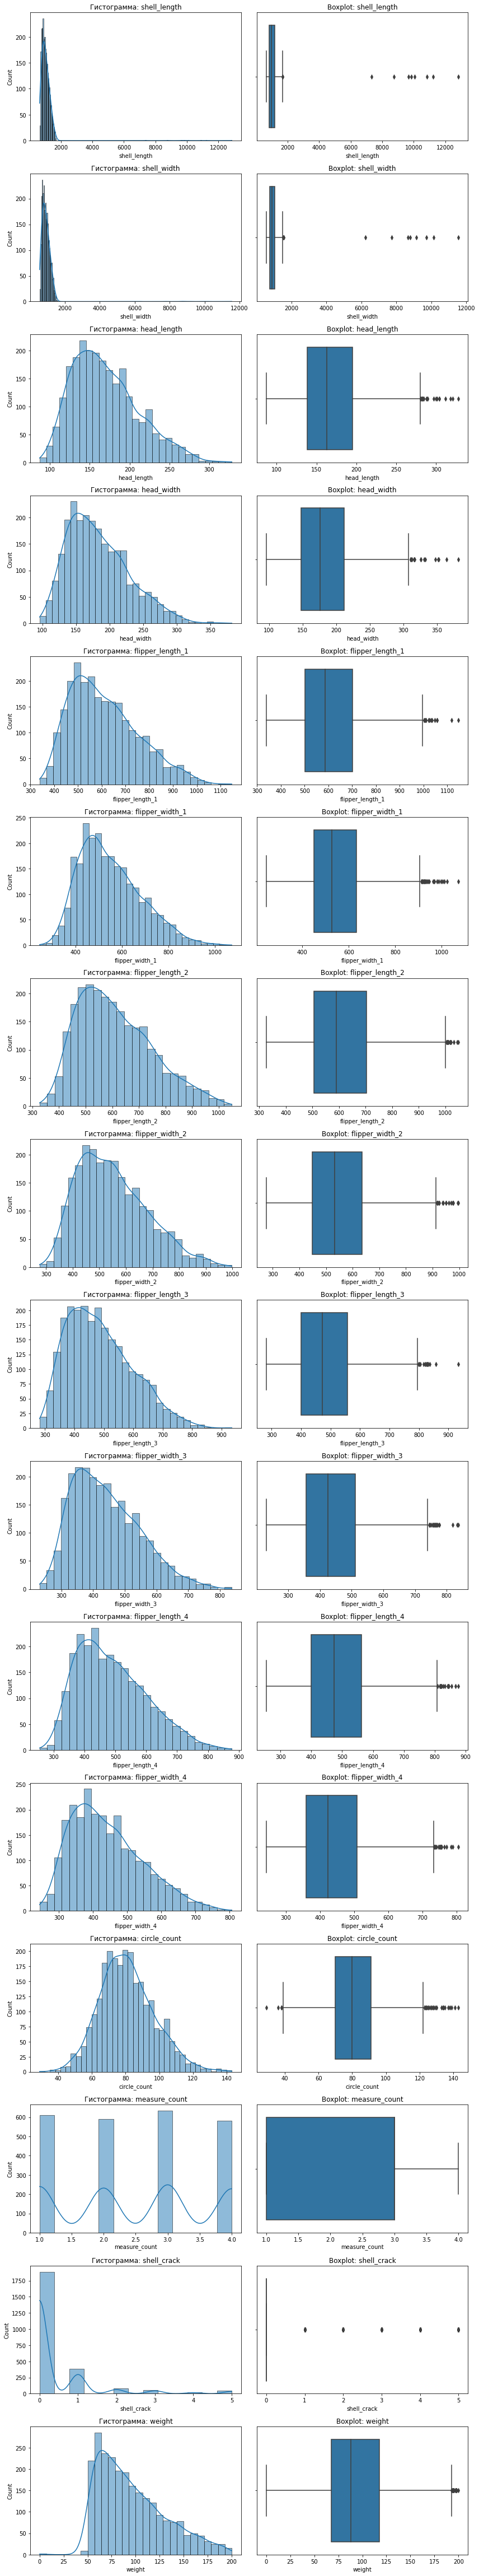

In [30]:
# Строим гистограмму распределения и ящик с усами
cols = df_mydas.columns

fig, axes = plt.subplots(len(cols), 2, figsize=(12, 4 * len(cols)))

for i, col in enumerate(cols):
    sns.histplot(df_mydas[col], kde=True, edgecolor='black', linewidth=0.5, ax=axes[i, 0])
    axes[i, 0].set_title(f'Гистограмма: {col}')
    
    sns.boxplot(x=df_mydas[col], ax=axes[i,1])
    axes[i, 1].set_title(f'Boxplot: {col}')
    
plt.tight_layout()
plt.show()

На графиках признаков `shell_length` и `shell_width` заметны аномально большие выбросы, превышающие остальную массу выбросов примерно в 10 раз. Возможно, именно к этому отсылало нас предупреждение в задание "...некоторые значения наш волонтёр ещё и на 10 умножил, думая, что они в сантиметрах указаны." То есть, возможно, это и есть те самые значения, которые по ошибке были умножены на 10.

Но прежде чем принимать это за факт и сразу делить выбросы на 10, стоит проверить гипотезу количественно. Посмотрим, во сколько раз конкретно "выбросные" значения `shell_length`/`shell_width` больше основной массы.

In [31]:
# Считаем межквартильный размах (IQR) для shell_length и shell_width
for col in ['shell_length', 'shell_width']:
    q1 = df_mydas[col].quantile(0.25)
    q3 = df_mydas[col].quantile(0.75)
    iqr = q3 - q1
    upper_bound = q3 + 1.5 * iqr
    
    normal_median = df_mydas.loc[df_mydas[col] <= upper_bound, col].median()
    outliers = df_mydas.loc[df_mydas[col] > upper_bound, col]
    
    print(f'---{col}---')
    print(f'Верхняя граница (IQR): {upper_bound:.1f}')
    print(f'Медиана нормальных значений: {normal_median:.1f}')
    print(f'Количество выбросов: {len(outliers)}')
    print(f'Во сколько раз выбрасы больше медианы:')
    print((outliers / normal_median).round(1).sort_values().to_list())
    print()

---shell_length---
Верхняя граница (IQR): 1674.5
Медиана нормальных значений: 978.0
Количество выбросов: 10
Во сколько раз выбрасы больше медианы:
[1.7, 1.7, 7.5, 8.9, 9.9, 10.1, 10.3, 11.1, 11.5, 13.1]

---shell_width---
Верхняя граница (IQR): 1511.6
Медиана нормальных значений: 887.0
Количество выбросов: 11
Во сколько раз выбрасы больше медианы:
[1.7, 1.7, 1.8, 7.0, 8.7, 9.8, 9.9, 10.3, 10.9, 11.4, 13.0]



Cписок неоднородный. Большинство значений группируются в диапазоне ~7-13 (в среднем близко к 10), но два значения в `shell_length` и 3 в `shell_width` сильно выбиваются - они всего в 1.7-1.8 раза больше медианы.

По 8 значений в обоих столбцах с коэффициентом ~7-13, вероятно, являются той самой ошибкой умножения на 10. А значения с коэффициентом ~1.7 - вероятно, просто крупные особи, естественный выброс.

Поделим на 10 те значения `shell_length` и `shell_width`, которые сильно отличаются от "натуральных" выбросов (в 7-13 раз выше медианы)

       shell_length  shell_width
count   2457.000000  2486.000000
mean    1018.436304   918.970233
std      222.149470   203.241558
min      645.000000   564.000000
25%      837.000000   752.000000
50%      979.000000   887.000000
75%     1168.000000  1054.000000
max     1683.000000  1554.000000


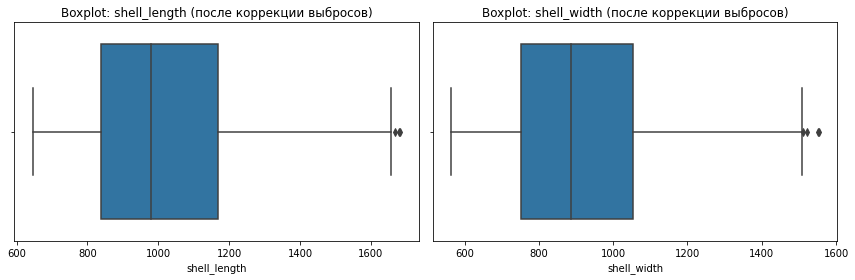

In [32]:
# Делим на 10 те значения shell_length/shell_width, которые в разы больше медианы нормальных значений
for col in ['shell_length', 'shell_width']:
    q1 = df_mydas[col].quantile(0.25)
    q3 = df_mydas[col].quantile(0.75)
    iqr = q3 - q1
    upper_bound = q3 + 1.5 * iqr
    
    normal_median = df_mydas.loc[df_mydas[col] <= upper_bound, col].median()
    
    mask_x10 = (df_mydas[col] > upper_bound) & (df_mydas[col] / normal_median > 5)
    df_mydas.loc[mask_x10, col] = df_mydas.loc[mask_x10, col] / 10
    
# Проверяем результат исправления: смотрим на статистику и boxplot после деления на 10
print(df_mydas[['shell_length', 'shell_width']].describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df_mydas['shell_length'], ax=axes[0])
axes[0].set_title('Boxplot: shell_length (после коррекции выбросов)')

sns.boxplot(x=df_mydas['shell_width'], ax=axes[1])
axes[1].set_title('Boxplot: shell_width (после коррекции выбросов)')

plt.tight_layout()
plt.show()

После коррекции `mean` и `median` близки друг к другу (1018 против 979 для `shell_length`, 919 против 887 для `shell_width`), явного искажения из-за экстремальных выбросов больше не видно.

При анализе распределений признаков на гистограммах и boxplot'ах обнаружены выбросы в `shell_length` и `shell_width` с коэффициентом отклонения от медианы ~7-13, что соответствует описанной заказчиком ошибке умножения значений на 10. Эти значения скорректированы делением на 10. Помимо них, в этих же и остальных признаках (`head_length`, `head_width`, `flipper_n`, `circle_count`) присутствуют единичные выбросы с коэффициентом ~1.7–1.8 от медианы, которые, предположительно, являются естественной вариативностью размеров крупных особей, а не ошибкой данных. Их решено не удалять и не изменять.

---

### Масштаб признаков
Проверим, одинаков ли масштаб признаков. 

Если он различается, предложим решение этой проблемы.

Смотрим на масштаб. Самый простой способ - сравнить диапазоны (min/max) и std по всем числовым признакам через `describe()`:

In [33]:
# Смотрим масштаб признаков. Транспонируем для удобства
df_mydas.describe().T

,count,mean,std,min,25%,50%,75%,max
shell_length,2457.0,1018.436304,222.149470,645.0,837.00000,979.0,1168.0000,1683.000
shell_width,2486.0,918.970233,203.241558,564.0,752.00000,887.0,1054.0000,1554.000
head_length,2451.0,169.723378,41.335454,87.0,138.00000,163.0,195.0000,328.000
head_width,2451.0,183.321093,45.477540,96.0,148.00000,176.0,212.0000,382.000
flipper_length_1,2486.0,612.010459,142.589526,339.0,502.00000,587.0,702.0000,1147.000
flipper_width_1,2486.0,549.364441,131.859104,245.0,449.00000,527.0,632.0000,1072.000
flipper_length_2,2486.0,611.890185,138.991986,327.0,505.00000,591.0,704.0000,1049.000
flipper_width_2,2486.0,550.253017,130.856316,276.0,449.00000,533.0,635.0000,997.000
flipper_length_3,2457.0,487.262922,110.435270,282.0,400.00000,473.0,558.0000,934.000
flipper_width_3,2457.0,440.667481,105.532073,231.0,357.00000,425.0,511.0000,837.000


Смотрим на диапазоны: 
- У `measure_count` и `shell_crack` совсем маленький масшаб (1-4 и 0-5 соответственно).
- Хоть у `circle_count` масштаб на порядок больше (29 - 143), чем у `measure_count` и `shell_crack`, но всё же значительно меньше остальной массы признаков
- `shell_*`, `head_*` и `flipper_*` признаки на порядок или два выше (сотни-тысячи)

Регулированные модели (Ridge, Lasso) штрафуют коэффициенты по их величине. Если признаки в разных масштабах, штраф сильнее давит на признаки с маленькими значениями. Градиентный спуск сходится намного хуже и медленнее, если признаки не приведены к одному масштабу.

Нужно масштабирование. Однако, это нужно сделать после разделения на тренировочную, валидационную и тестовую выборки, чтобы не допустить утечки данных, из-за чего оценка качества модели может оказаться завышенной.

---

### Корреляционный анализ
Проанализируем корреляцию между признаками и целевой переменной с помощью вычислений и графически. 

Определим, все ли признаки нужны для дальнейшей работы.

Посмотрим на корреляцию признаков с целевой переменной `weight`. Начнём с числовых значений, посчитаем корреляцию Пирсона всех признаков с `weight` и отсортируем по силе связи.

In [34]:
# Считаем корреляцию Пирсона всех признаков с целевой переменной weight
corr_with_target = df_mydas.corr()['weight'].drop('weight').sort_values(key=abs, ascending=False)
corr_with_target

shell_length        0.978047
shell_width         0.962173
flipper_length_1    0.920193
flipper_length_4    0.919410
flipper_length_2    0.917602
flipper_length_3    0.915939
flipper_width_2     0.897546
flipper_width_4     0.896082
flipper_width_3     0.895270
flipper_width_1     0.892027
head_length         0.869587
head_width          0.863186
circle_count        0.506291
shell_crack         0.171841
measure_count      -0.031414
Name: weight, dtype: float64

Сразу выполним визуализацию тепловой картой:

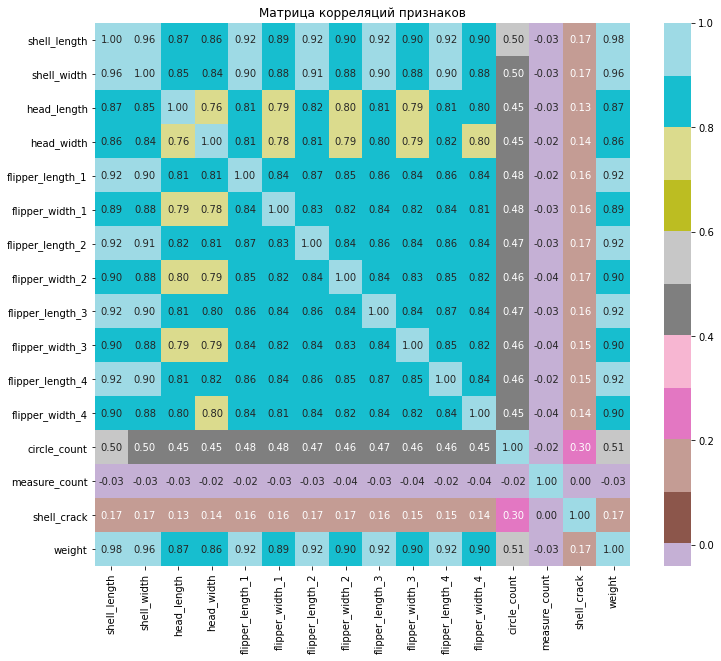

In [35]:
# Визуализируем полную матрицу корреляций тепловой картой
plt.figure(figsize=(12, 10))
sns.heatmap(df_mydas.corr(), annot=True, fmt='.2f', cmap='tab20', center=0)
plt.title('Матрица корреляций признаков')
plt.show()

- Корреляция признака `measure_count` с целевой переменной `weight` равна -0.03, это практически ноль. То есть признак не несёт линейной связи с целевой переменной. Количество измерений черепахи TurtleCV не влияет на её реальную массу. Этот признак можно исключить.
- Признак `circle_count` демонстрирует умеренную связь (0.51) с целевой переменной `weight`. Это подтверждает дополнительную информацию из задания о связи колец с возрастом, а следовательно и с массой. 
- Признак `shell_crack` демонстрирует низкую корреляцию с целевой переменной. Вероятно, потому что это не размерный признак, а признак состояния, из-за чего признак имеет скорее нелинейную связь с целевой переменной. Стоит провести дополнительную проверку с помощью коэффициента `phik`.
- `shell_*`, `head_*` и `flipper_*` признаки демонстрируют высокую корреляцию с целевой переменной `weight` (от 0.86 до 0.98), что логично, ведь это чисто размерные признаки, непосредственно влияющие на массу черепахи. Однако эти признаки также демонстрируют высокую корреляцию между собой на уровне 0.8-0.9. Это также ожидаемо, ведь черепаха растёт в целом, а не отдельными частями. Но это **вопрос мультиколлинеарности** - стоит проверить с помощью `phik`.

---

### Мультиколлинеарность
Проверим данные на мультиколлинеарность и решим, можно ли её устранить.

Посчитаем матрицу коэффициентов `phik`. Она, в отличие от Пирсона, улавливает и нелинейные зависимости между признаками и с целевой переменной.

In [36]:
# Устанавливаем пакет phik
!pip install phik

# Импортируем библиотеку phik
import phik

In [37]:
# Считаем корреляцию Пирсона всех признаков с целевой переменной weight
phik_corr_with_target = df_mydas.phik_matrix()['weight'].drop('weight').sort_values(key=abs, ascending=False).round(2)
phik_corr_with_target

interval columns not set, guessing: ['shell_length', 'shell_width', 'head_length', 'head_width', 'flipper_length_1', 'flipper_width_1', 'flipper_length_2', 'flipper_width_2', 'flipper_length_3', 'flipper_width_3', 'flipper_length_4', 'flipper_width_4', 'circle_count', 'measure_count', 'shell_crack', 'weight']


shell_length        0.89
shell_width         0.85
flipper_length_1    0.78
flipper_length_3    0.76
flipper_length_4    0.76
flipper_length_2    0.76
flipper_width_4     0.75
flipper_width_2     0.75
flipper_width_3     0.74
flipper_width_1     0.74
head_length         0.71
head_width          0.70
circle_count        0.39
shell_crack         0.24
measure_count       0.06
Name: weight, dtype: float64

interval columns not set, guessing: ['shell_length', 'shell_width', 'head_length', 'head_width', 'flipper_length_1', 'flipper_width_1', 'flipper_length_2', 'flipper_width_2', 'flipper_length_3', 'flipper_width_3', 'flipper_length_4', 'flipper_width_4', 'circle_count', 'measure_count', 'shell_crack', 'weight']


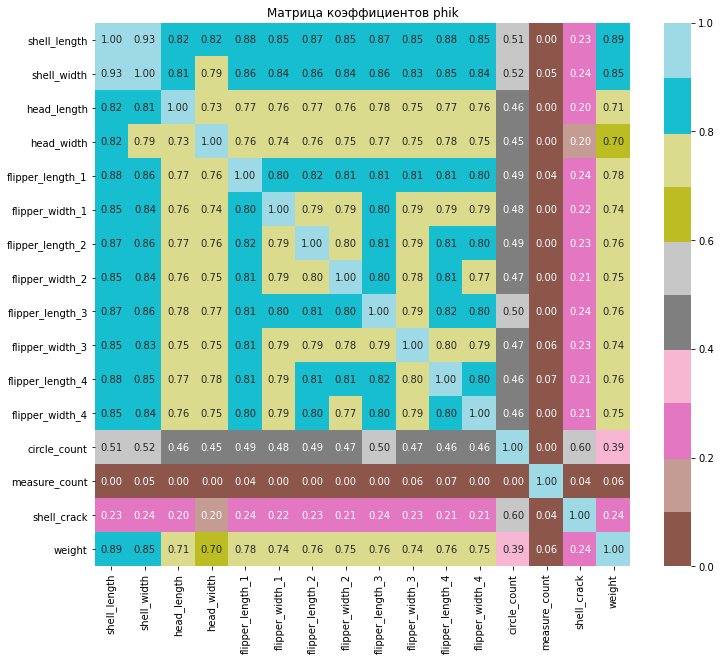

In [38]:
# Считаем матрицу коэффициентов phik
phik_overview = df_mydas.phik_matrix()

plt.figure(figsize=(12, 10))
sns.heatmap(phik_overview, annot=True, fmt='.2f', cmap='tab20', center=0)
plt.title('Матрица коэффициентов phik')
plt.show()

- Признак `circle_count` демонстрирует меньшую связь с целевой переменной `weight`, чем по Пирсону (0.39 против 0.5). Но связь остаётся вполне уверенной. Также интересна повышенная связь `circle_count` с `shell_crack` (с 0.3 повысилась до 0.6).
- Признак `shell_crack`, напротив, повысил свою связь с целевой переменной с 0.17 до 0.24. `phik` дополнительно уловил некую нелинейную связь между ними. Вероятно, количество трещин косвенно указывает на возраст животного (чем больше трещин, тем старше черепаха), а черепахи взрослея становятся больше и тяжелее.
- Признак `measure_count` слега повысил свою связь с -0.03 до 0.06, но это всё равно практически 0, что подтверждает вывод по Пирсону - признак стоит исключить.
- Все размерные признаки (`shell_*`, `head_*` и `flipper_*`) чуть просели. Это ожидаемо, ведь у них связь с `weight` в основном именно линейная. `phik` вносит небольшую погрешность за счёт дискретизации непрерывной величины.

**По мультиколлинеарности:**
- Все размерные признаки (`shell_*`, `head_*` и `flipper_*`) коррелируют между собой в диапазоне 0.73-0.93 - это высокие значения. Мультиколлинеарность выражена сильно и затрагивает практически весь блок габаритов.
- Особенно тесная связь между признаками `shell_length` и `shell_width` (0.93) - почти дублирующая информация.

Причина такой сильной коллинеарности объяснима - части тела растут соразмерно друг другу с ростом черепахи, поэтому связаны почти линейно между собой. Однако это грозит ненадёжностью оценки важности признаков по коэффициентам предсказания разных моделей.

Мультиколлинеарность можно устранить с помощью удаления явно избыточных признаков или их агрегирования и регуляризации. Длину и толщину частей тела можно объединить в агрегатную величину размера части тела. Ridge-регрессия штрафует большие коэффициенты и тем самым сглаживает нестабильность, вызванную коллинераностью - коэффициенты становятся более устойчивыми.

**План устранения мультиколлинеарности:**
- **Панцирь.** Объеденить `shell_length` и `shell_width` в один агрегированный признак вместо двух почти дублирующих друг друга габаритов панциря.
- **Голова.** Аналогично объединить `head_length` и `head_width` в один признак. Несмотря на чуть более умеренную корреляцию (0.73), решили пойти тем же путём для единообразия подхода.
- **Ласты, шаг 1.** Для каждой из четырёх ласт объединить её `length` и `width` в один признак "размер ласты N".
- **Ласты, шаг 2.** Так как между собой сильно скоррелированы уже сами эти 4 ласты-признака, агрегируем их в один общий признак - средний размер ласты по всем четырём. 

Тогда из 12 исходных размерных признаков получим 3 агрегированных. `circle_count` и `shell_crack` не трогаем, так как их связь с остальными признаками умренная, явной избыточности нет. 

Создадим копию датафрейма перед изменениями.

In [39]:
df_mydas_befor_agr = df_mydas.copy()

Агрегировать будем средним значением, оно сохраняет масштаб исходных признаков (в мм), что удобно для интерпритации. Также учтём наличие пропусков - используем `skipna=False`, если хотя бы одно из двух значений пропущено, в агрегированный признак также запишется пропуск.

- **Панцирь**

In [40]:
# Объединяем длину и ширину панциря в один агрегированный признак shell_size
df_mydas['shell_size'] = df_mydas[['shell_length', 'shell_width']].mean(axis=1, skipna=False)

# Посмотрим статистику агрегированного признака
df_mydas[['shell_length', 'shell_width', 'shell_size']].describe().round(2)

,shell_length,shell_width,shell_size
count,2457.00,2486.00,2457.00
mean,1018.44,918.97,968.57
std,222.15,203.24,210.04
min,645.00,564.00,634.00
25%,837.00,752.00,795.50
50%,979.00,887.00,934.50
75%,1168.00,1054.00,1112.00
max,1683.00,1554.00,1609.00


- **Голова**

In [41]:
# Объединяем длину и ширину головы в один агрегированный признак head_size
df_mydas['head_size'] = df_mydas[['head_length', 'head_width']].mean(axis=1, skipna=False)

# Посмотрим статистику агрегированного признака
df_mydas[['head_length', 'head_width', 'head_size']].describe().round(2)

,head_length,head_width,head_size
count,2451.00,2451.00,2451.00
mean,169.72,183.32,176.52
std,41.34,45.48,40.77
min,87.00,96.00,95.00
25%,138.00,148.00,143.50
50%,163.00,176.00,170.00
75%,195.00,212.00,203.00
max,328.00,382.00,331.00


- **Ласты**

In [42]:
# Шаг 1. Для каждой из 4 ласт объединяем длину и ширину
for n in range(1, 5):
    df_mydas[f'flipper_size_{n}'] = df_mydas[[f'flipper_length_{n}', 
                                             f'flipper_width_{n}']].mean(axis=1, skipna=False)
    
# Посмотрим статистику агрегированного признака    
for n in range(1, 5):
    display(df_mydas[[f'flipper_length_{n}', f'flipper_width_{n}', f'flipper_size_{n}']].describe().round(2))

,flipper_length_1,flipper_width_1,flipper_size_1
count,2486.00,2486.00,2486.00
mean,612.01,549.36,580.69
std,142.59,131.86,131.51
min,339.00,245.00,320.50
25%,502.00,449.00,476.50
50%,587.00,527.00,557.00
75%,702.00,632.00,667.00
max,1147.00,1072.00,1034.00


,flipper_length_2,flipper_width_2,flipper_size_2
count,2486.00,2486.00,2486.00
mean,611.89,550.25,581.07
std,138.99,130.86,129.50
min,327.00,276.00,330.50
25%,505.00,449.00,477.50
50%,591.00,533.00,559.00
75%,704.00,635.00,665.38
max,1049.00,997.00,989.50


,flipper_length_3,flipper_width_3,flipper_size_3
count,2457.00,2457.00,2457.00
mean,487.26,440.67,463.97
std,110.44,105.53,103.64
min,282.00,231.00,272.50
25%,400.00,357.00,380.00
50%,473.00,425.00,447.00
75%,558.00,511.00,533.00
max,934.00,837.00,797.50


,flipper_length_4,flipper_width_4,flipper_size_4
count,2457.00,2457.00,2457.00
mean,489.18,440.98,465.08
std,112.56,104.57,104.06
min,254.00,243.00,268.00
25%,400.00,359.00,381.00
50%,473.00,423.00,448.50
75%,563.00,509.00,533.50
max,877.00,806.00,831.00


In [43]:
# Шаг 2. Полученные 4 ласт-признака тоже сильно коррелируют между собой - агрегируем их в один признак
flipper_size_cols = [f'flipper_size_{n}' for n in range(1, 5)]
df_mydas['flipper_size'] = df_mydas[flipper_size_cols].mean(axis=1, skipna=False)

# Посмотрим статистику агрегированного признака    
df_mydas[['flipper_size_1', 'flipper_size_2', 'flipper_size_3', 'flipper_size_4', 'flipper_size']].describe().round(2)

,flipper_size_1,flipper_size_2,flipper_size_3,flipper_size_4,flipper_size
count,2486.00,2486.00,2457.00,2457.00,2457.00
mean,580.69,581.07,463.97,465.08,522.67
std,131.51,129.50,103.64,104.06,113.34
min,320.50,330.50,272.50,268.00,334.75
25%,476.50,477.50,380.00,381.00,429.88
50%,557.00,559.00,447.00,448.50,505.75
75%,667.00,665.38,533.00,533.50,597.12
max,1034.00,989.50,797.50,831.00,860.88


- Удаляем все исходные и промежуточные признаки, которые заменили агрегатами

In [44]:
# Удаляем лишние признаки
cols_to_drop = ['shell_length', 'shell_width', 'head_length', 'head_width',
                 'flipper_length_1', 'flipper_width_1',
                 'flipper_length_2', 'flipper_width_2',
                 'flipper_length_3', 'flipper_width_3',
                 'flipper_length_4', 'flipper_width_4',
                 'measure_count'] + flipper_size_cols

df_mydas = df_mydas.drop(columns=cols_to_drop)
df_mydas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2486 entries, 0 to 2485
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   circle_count  2486 non-null   int64  
 1   shell_crack   2486 non-null   float64
 2   weight        2486 non-null   float64
 3   shell_size    2457 non-null   float64
 4   head_size     2451 non-null   float64
 5   flipper_size  2457 non-null   float64
dtypes: float64(5), int64(1)
memory usage: 116.7 KB


**Пересчитаем корреляцию Пирсона** всех признаков с целевой переменной `weight` после агрегации

In [45]:
# Пересчитаем корреляцию Пиросна
corr_with_target = df_mydas.corr()['weight'].drop('weight').sort_values(key=abs, ascending=False).round(2)
corr_with_target

shell_size      0.98
flipper_size    0.98
head_size       0.92
circle_count    0.51
shell_crack     0.17
Name: weight, dtype: float64

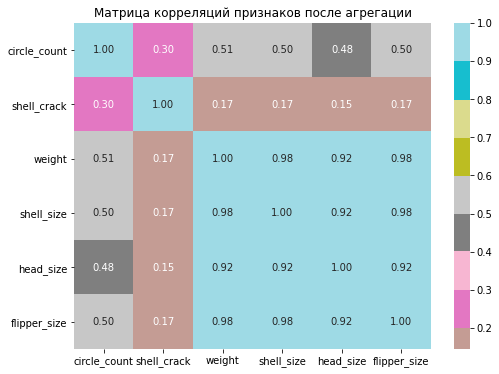

In [46]:
# Пересчитаем полную матрицу корреляции между признаками
plt.figure(figsize=(8, 6))
sns.heatmap(df_mydas.corr(), annot=True, fmt='.2f', cmap='tab20', center=0)
plt.title('Матрица корреляций признаков после агрегации')
plt.show()

**Вывод по корреляционному анализу и устранению мультиколлинеарности:**

Все размерные признаки (панцирь, голова, ласты) показали сильную линейную и нелинейную связь с целевой переменной `weight` (Пирсон и phik от 0.71 до 0.98), в то время как `measure_count` не продемонстрировал значимой связи (~0) и был исключён из датасета. Исходные 12 размерных признаков были агрегированы в три укрупнённых (`shell_size`, `head_size`, `flipper_size`), что устранило избыточную корреляцию внутри каждой части тела, однако между самими агрегатами сохранилась высокая мультиколлинеарность (0.92–0.98), объяснимая пропорциональным ростом всех частей тела черепахи. Признаки `circle_count` и `shell_crack` сохранены несмотря на более слабую корреляцию с `weight`, так как несут отличную от размерных признаков информацию (возраст и состояние панциря), которую дальше сокращать сложно без потери полезных данных; оставшуюся мультиколлинеарность между размерными признаками планируется компенсировать регуляризацией (`Ridge`) на этапе обучения моделей.

---

## Предобработка данных

### Разделение на выборки
Разделим данные на выборки: обучающую (60%), валидационную (20%) и тестовую (20%). 

В реальных проектах стараются писать код предобработки так, чтобы предотвратить утечку данных. Это проще сделать, если сразу поделить данные.

In [47]:
# Отделим признаки и целевую переменную (weight)
X = df_mydas.drop(columns = 'weight').values
y = df_mydas['weight'].values

# Выделим на train_val и test
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42, shuffle = True
)

# Выделите на train и val
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size = 0.25, random_state = 42, shuffle = True
)

# Проверим размерности полученных переменных
print(X_train.shape, X_val.shape, X_test.shape, y_train.shape, y_val.shape, y_test.shape)

(1491, 5) (497, 5) (498, 5) (1491,) (497,) (498,)


Данные разделены на обучающую, валидационную и тестовую выборки в пропорции 60/20/20 (1491/497/498 строк) с помощью двух последовательных вызовов `train_test_split` и фиксированным `random_state=42` для воспроизводимости. Разбиение выполнено до дальнейшей обработки пропусков и масштабирования признаков, чтобы параметры этих преобразований рассчитывались только по обучающей выборке и не допустить утечки данных.

---

### Обработка пропусков
При необходимости заполним их средними (медианными) значениями. Рассчитаем заполнитель только по обучающей выборке: это ещё одно правило для предотвращения утечки.

После разбиения на выборки в трёх признаках (`shell_size`, `head_size`, `flipper_size`) остались пропуски, унаследованные от агрегации. Чтобы их корректно заполнить и не допустить утечки данных, медиану нужно посчитать только по `X_train`.

In [48]:
# Считаем медиану каждого признака только по обучающей выборке
train_medians = np.nanmedian(X_train, axis=0)

# Считаем пропуски по каждой выборке до заполнения
missing_before_train = np.isnan(X_train).sum(axis=0)
missing_before_val = np.isnan(X_val).sum(axis=0)
missing_before_test = np.isnan(X_test).sum(axis=0)

# Заполняем пропуски рассчитанными медианами train во всех трёх выборках
X_train = np.where(np.isnan(X_train), train_medians, X_train)
X_val = np.where(np.isnan(X_val), train_medians, X_val)
X_test = np.where(np.isnan(X_test), train_medians, X_test)

# Проверим, что пропусков не осталось
print('Количество пропусков до заполнения по каждой выборке')
print(f'Тренировочная выборка: {missing_before_train}')
print(f'Валидационная выборка: {missing_before_val}')
print(f'Тестовая выборка: {missing_before_test}')
print(f'Суммарное количество пропусков: {missing_before_train + missing_before_val + missing_before_test}')
print('Количество пропусков после заполнения медианами:')
print(np.isnan(X_train).sum(axis=0), np.isnan(X_val).sum(axis=0), np.isnan(X_test).sum(axis=0))

Количество пропусков до заполнения по каждой выборке
Тренировочная выборка: [ 0  0 16 20 14]
Валидационная выборка: [0 0 6 7 8]
Тестовая выборка: [0 0 7 8 7]
Суммарное количество пропусков: [ 0  0 29 35 29]
Количество пропусков после заполнения медианами:
[0 0 0 0 0] [0 0 0 0 0] [0 0 0 0 0]


Отлично, всё чисто — [0 0 0 0 0] по всем трём выборкам, пропуски заполнены медианами `train`, утечки нет.
- В признаке `shell_size` было заполнено 29 пропусков;
- В признаке `head_size` было заполнено 35 пропусков;
- В признаке `flipper_size` было заполнено 29 пропусков.

Пропуски в признаках `shell_size`, `head_size` и `flipper_size` заполнены медианными значениями, рассчитанными строго по обучающей выборке `X_train`. Этими же медианами заполнены пропуски в `X_val` и `X_test`, что предотвращает утечку данных из валидационной и тестовой выборок в процесс обучения.

---

### Функция стандартизации признаков
Напишем функцию для стандартизации признаков.

Расчёт параметров масштабирования делаем только по обучающей выборке, чтобы не дать утечке ни малейшего шанса.

In [49]:
# Функция масштабирования признаков
def scale_data(X_train, X_val, X_test, method='standard'):
    if method == 'standard':
        mean = X_train.mean(axis=0)
        std = X_train.std(axis=0)
        X_train_scaled = (X_train - mean) / std
        X_val_scaled = (X_val - mean) / std
        X_test_scaled = (X_test - mean) / std
    elif method == 'minmax':
        min_val = X_train.min(axis=0)
        max_val = X_train.max(axis=0)
        X_train_scaled = (X_train - min_val) / (max_val - min_val)
        X_val_scaled = (X_val - min_val) / (max_val - min_val)
        X_test_scaled = (X_test - min_val) / (max_val - min_val)
    else:
        raise ValueError("Неверный метод масштабирования. Используйте 'standard' или `minmax`.")
    return X_train_scaled, X_val_scaled, X_test_scaled
        
X_train_scaled, X_val_scaled, X_test_scaled = scale_data(X_train, X_val, X_test, 'standard')

# Проверка: вывод среднего и стандартного отклонения полученных выборок
print("Train mean:", X_train_scaled.mean().mean().round(2))
print("Train std:", X_train_scaled.std().mean().round(2))
print("Val mean:", X_val_scaled.mean().mean().round(2))
print("Val std:", X_val_scaled.std().mean().round(2))
print("Test mean:", X_test_scaled.mean().mean().round(2))
print("Test std:", X_test_scaled.std().mean().round(2))

Train mean: -0.0
Train std: 1.0
Val mean: -0.05
Val std: 0.99
Test mean: -0.01
Test std: 0.98


Написана функция `scale_data`, реализующая стандартизацию (`method='standard'`) и нормализацию (`method='minmax'`) признаков. Параметры масштабирования (`mean/std` для стандартизации, `min/max` для нормализации) рассчитываются только по обучающей выборке `X_train` и применяются в неизменном виде к `X_val` и `X_test`, что исключает утечку данных.

Проверка на стандартизированных данных подтвердила корректность: среднее и `std` по `X_train` вышли ровно 0.0 и 1.0, а для `X_val` (-0.05 / 0.99) и `X_test` (-0.01 / 0.98) значения близки к этим ориентирам, но не совпадают точно - это ожидаемо, так как `val/test` масштабировались параметрами `train`, а не своими собственными.

---

### Нормализация признаков

Применим написанную функцию `scale_data` для нормализации признаков (`method='minmax'`)

In [50]:
# Применяем нормализацию (min-max) к трём выборкам
X_train_norm, X_val_norm, X_test_norm = scale_data(X_train, X_val, X_test, 'minmax')

# Проверка: min и max по train должны быть строго 0 и 1
print("Train min:", X_train_norm.min(axis=0).mean().round(2))
print("Train max:", X_train_norm.max(axis=0).mean().round(2))

# У val/test min/max могут немного выходить за [0, 1]
print("Val min:", X_val_norm.min(axis=0).mean().round(2), " Val max:", X_val_norm.max(axis=0).mean().round(2))
print("Test min:", X_test_norm.min(axis=0).mean().round(2), " Test max:", X_test_norm.max(axis=0).mean().round(2))

Train min: 0.0
Train max: 1.0
Val min: 0.03  Val max: 0.97
Test min: 0.02  Test max: 0.99


Нормализация (min-max) на `X_train` даёт ровно ожидаемые границы - минимум 0.0, максимум 1.0 по всем признакам, что подтверждает корректность расчёта параметров min/max. На `X_val` (0.03–0.97) и `X_test` (0.02–0.99) значения лежат внутри диапазона [0, 1], не выходя за его пределы. В данном случае это означает, что во всех признаках валидационной и тестовой выборок не встретилось значений более экстремальных, чем в `train`, и утечки данных при этом не допущено, так как параметры масштабирования взяты только из обучающей выборки.

---

### Подготовка датасетов для обучения моделей.
Подготовим несколько датасетов из трёх выборок каждый для дальнейшего обучения моделей с разным способом масштабирования: без масштабирования, с нормализацией, со стандартизацией.

In [51]:
# Собираем три варианта датасетов (без масштабирования, нормализованный, стандартизированный)
# в единую структуру для удобного перебора при обучении моделей
datasets = {
    'no_scaling': {
        'X_train': X_train, 'X_val': X_val, 'X_test': X_test
    },
    'normalized': {
        'X_train': X_train_norm, 'X_val': X_val_norm, 'X_test': X_test_norm
    },
    'standardized': {
        'X_train': X_train_scaled, 'X_val': X_val_scaled, 'X_test': X_test_scaled
    },
}

# Проверим, что во всех вариантах размерности совпадают
for name, data in datasets.items():
    print(name, data['X_train'].shape, data['X_val'].shape, data['X_test'].shape)

no_scaling (1491, 5) (497, 5) (498, 5)
normalized (1491, 5) (497, 5) (498, 5)
standardized (1491, 5) (497, 5) (498, 5)


---

**Вывод по разделу предобработки данных**

Данные разделены на обучающую, валидационную и тестовую выборки (60/20/20, random_state=42), после чего оставшиеся пропуски в агрегированных признаках заполнены медианами, рассчитанными строго по обучающей выборке. Написана единая функция `scale_data` для стандартизации и нормализации признаков, параметры которой также рассчитываются только по `X_train` - на выходе получены три равнозначных по составу датасета (без масштабирования, нормализованный, стандартизированный), собранные в структуру `datasets` для последующего перебора моделей; на каждом шаге принцип предотвращения утечки данных соблюдён.


---

## Обучение моделей

### Построение базовой модели.
Построим базовую модель (дамми), с которой будем сравнивать все остальные. Если они будут хуже базовой по качеству, это будет означать, что при обучении что-то пошло не так.

Дамми-модель (baseline) - это модель без какого-либо реального обучения, она просто предсказывает одно и то же значение для всех объектов. Смысл в том, чтобы иметь "нижнюю планку" качества: любая настоящая модель, которая не может обыграть даже такую примитивную стратегию, явно обучена неправильно.

In [52]:
# Импортируем необходимую библиотеку
from sklearn.dummy import DummyRegressor

In [53]:
# Построение базовой модели
dammy_no_scaled = DummyRegressor()
dammy_normalized = DummyRegressor()
dammy_standardized = DummyRegressor()

# Обучение
dammy_no_scaled.fit(datasets['no_scaling']['X_train'], y_train)
dammy_normalized.fit(datasets['normalized']['X_train'], y_train)
dammy_standardized.fit(datasets['standardized']['X_train'], y_train)

# Коэффициенты модели
print(np.round(dammy_no_scaled.constant_))
print(np.round(dammy_normalized.constant_))
print(np.round(dammy_standardized.constant_))

[[96.]]
[[96.]]
[[96.]]


Дамми не чувствителен к масштабу признаков, для неё не важно, какой из трёх датасетов (`no_scaling`/`normalized`/`standardized`) брать — результат одинаковый.

---

### Обучение линейных моделей
Обучим несколько архитектур линейных моделей. Они могут различаться по ряду черт: набором отобранных признаков, масштабом признаков, установленными гиперпараметрами, функциями потерь. Попробуем обучить следующие модели:
   - `LinearRegression`;
   - `Lasso` (L1-регуляризация);
   - `Ridge` (L2-регуляризация);
   - `SGDRegressor`.
   
   Обязательно попробуем модели с разными значениями гиперпараметра `loss`.
- **Бонусное задание.** Подумайте, можно ли улучшить модели за счёт создания новых признаков: например, умножив длину ласт на ширину. Проверьте, усилится ли корреляция нового признака с целевой переменной, возрастёт ли благодаря ему качество модели.

- `LinearRegression`;

In [54]:
# Построение и обучение модели LinearRegression
linreg_no_scaled = LinearRegression()
linreg_normalized = LinearRegression()
linreg_standardized = LinearRegression()

linreg_no_scaled.fit(datasets['no_scaling']['X_train'], y_train)
linreg_normalized.fit(datasets['normalized']['X_train'], y_train)
linreg_standardized.fit(datasets['standardized']['X_train'], y_train)

# Коэффициенты модели LinearRegression
print(f'Веса LinearRegression модели без масштабирования: {np.round(linreg_no_scaled.coef_, 2)}')
print(f'Веса LinearRegression модели с нормализацией: {np.round(linreg_normalized.coef_, 2)}')
print(f'Веса LinearRegression модели со стандартизацией: {np.round(linreg_standardized.coef_, 2)}')

Веса LinearRegression модели без масштабирования: [0.03 0.32 0.07 0.11 0.13]
Веса LinearRegression модели с нормализацией: [ 3.61  1.61 67.73 26.38 70.06]
Веса LinearRegression модели со стандартизацией: [ 0.52  0.32 14.91  4.57 15.04]


`LinearRegression` ведёт себя предсказуемо на всех трёх датасетах - коэффициенты пропорционально масштабируются вместе с признаками (маленькие на `no_scaling`, крупные на `normalized`, средние на `standardized`), Модель везде видит одну и ту же зависимость, просто выражает её в разных единицах. Регуляризации нет, поэтому все веса ненулевые.

- `Lasso` (L1-регуляризация);

In [55]:
# Построение и обучение модели Lasso
lasso_no_scaled = Lasso()
lasso_normalized = Lasso()
lasso_standardized = Lasso()

lasso_no_scaled.fit(datasets['no_scaling']['X_train'], y_train)
lasso_normalized.fit(datasets['normalized']['X_train'], y_train)
lasso_standardized.fit(datasets['standardized']['X_train'], y_train)

# Коэффициенты модели Lasso
print(f'Веса Lasso модели без масштабирования: {np.round(lasso_no_scaled.coef_, 2)}')
print(f'Веса Lasso модели с нормализацией: {np.round(lasso_normalized.coef_, 2)}')
print(f'Веса Lasso модели со стандартизацией: {np.round(lasso_standardized.coef_, 2)}')

Веса Lasso модели без масштабирования: [0.03 0.   0.07 0.11 0.13]
Веса Lasso модели с нормализацией: [ 0.    0.   74.26  0.   62.76]
Веса Lasso модели со стандартизацией: [ 0.    0.   14.81  4.18 14.81]


Здесь эффект масштаба критичен. На `no_scaling` регуляризация почти не сработала (обнулился только `shell_crack`), так как признаки в мм и без того дают маленькие коэффициенты, штраф на них слабо действует. На `normalized`, наоборот, регуляризация оказалась чрезмерно агрессивной - обнулила 3 из 5 весов (`circle_count`, `shell_crack`, `head_size`), оставив только `shell_size` и `flipper_size`. На `standardized` эффект более сбалансированный: стабильно обнулились `circle_count` и `shell_crack` (слабо связанные с массой признаки), а три размерных признака сохранились. Это показывает, что `default alpha` у `Lasso` работает совершенно по-разному в зависимости от масштаба признаков, поэтому отбор признаков через L1 корректно интерпретировать только на standardized-варианте.

- `Ridge` (L2-регуляризация);

In [56]:
# Построение и обучение модели Ridge
ridge_no_scaled = Ridge()
ridge_normalized = Ridge()
ridge_standardized = Ridge()

ridge_no_scaled.fit(datasets['no_scaling']['X_train'], y_train)
ridge_normalized.fit(datasets['normalized']['X_train'], y_train)
ridge_standardized.fit(datasets['standardized']['X_train'], y_train)

# Коэффициенты модели Ridge
print(f'Веса Ridge модели без масштабирования: {np.round(ridge_no_scaled.coef_, 2)}')
print(f'Веса Ridge модели с нормализацией: {np.round(ridge_normalized.coef_, 2)}')
print(f'Веса Ridge модели со стандартизацией: {np.round(ridge_standardized.coef_, 2)}')

Веса Ridge модели без масштабирования: [0.03 0.32 0.07 0.11 0.13]
Веса Ridge модели с нормализацией: [ 4.26  1.68 66.58 29.23 67.88]
Веса Ridge модели со стандартизацией: [ 0.53  0.32 14.89  4.61 15.02]


Тут эффект мягче и заметнее через сжатие коэффициентов по сравнению с `LinearRegression` (веса чуть меньше по модулю на всех трёх датасетах, но ни один не обнулился), что и ожидается от L2-регуляризации при мультиколлинеарности между `shell_size`/`head_size`/`flipper_size`.

- `SGDRegressor`

In [57]:
# Построение и обучение модели SGDRegressor
sgdreg_no_scaled = SGDRegressor()
sgdreg_normalized = SGDRegressor()
sgdreg_standardized = SGDRegressor()

sgdreg_no_scaled.fit(datasets['no_scaling']['X_train'], y_train)
sgdreg_normalized.fit(datasets['normalized']['X_train'], y_train)
sgdreg_standardized.fit(datasets['standardized']['X_train'], y_train)

# Коэффициенты модели SGDRegressor
print(f'Веса SGDRegressor модели без масштабирования: {np.round(sgdreg_no_scaled.coef_, 2)}')
print(f'Веса SGDRegressor модели с нормализацией: {np.round(sgdreg_normalized.coef_, 2)}')
print(f'Веса SGDRegressor модели со стандартизацией: {np.round(sgdreg_standardized.coef_, 2)}')

Веса SGDRegressor модели без масштабирования: [-9.68683075e+10  1.93778839e+11 -3.82639773e+10 -6.49897750e+11
 -1.13799509e+11]
Веса SGDRegressor модели с нормализацией: [ 5.17  1.39 64.5  36.81 64.6 ]
Веса SGDRegressor модели со стандартизацией: [ 0.49  0.3  14.84  4.74 14.79]


Самый показательный случай: на `no_scaling` модель не сошлась - веса взорвались до порядка $10^{11}$, что говорит о численной нестабильности градиентного спуска на немасштабированных признаках (большой разброс значений в мм ломает шаг обучения). На `normalized` и `standardized` веса адекватны и близки к `LinearRegression`/`Ridge`. Это прямое подтверждение, что `SGDRegressor` требует обязательного масштабирования признаков - без него модель непригодна для использования.

Масштабирование не влияет на качество `LinearRegression`, критично важно для корректной работы `SGDRegressor` и определяет силу/направленность отбора признаков в `Lasso`. Для честного сравнения важности признаков между моделями и для дальнейшего анализа коэффициентов лучше всего подходит `standardized`-вариант - он даёт наиболее интерпретируемые и устойчивые веса среди всех трёх.

- Попробуем `SGDRegressor` с разными значениями гиперпараметра `loss`. Линейная модель может отличаться не только регуляризацией, но и функцией потерь, то есть тем, как именно штрафуются ошибки предсказания при обучении. Далее будем работать с `standardized`-вариантами.

Возьмём три варианта: `squared_error`, `huber`, `epsilon_insensitive`

In [58]:
!pip install --upgrade scikit-learn

In [59]:
import sklearn
print(sklearn.__version__)

1.6.1


In [60]:
# Обучаем SGDRegressor с разными функциями потерь на стандартизированных данных
sgd_squared = SGDRegressor(loss='squared_error', random_state=42, max_iter=5000)
sgd_huber = SGDRegressor(loss='huber', random_state=42, max_iter=5000)
sgd_epsilon = SGDRegressor(loss='epsilon_insensitive', random_state=42, max_iter=5000)

sgd_squared.fit(datasets['standardized']['X_train'], y_train)
sgd_huber.fit(datasets['standardized']['X_train'], y_train)
sgd_epsilon.fit(datasets['standardized']['X_train'], y_train)

# Коэффициенты моделей
print(f'Веса SGDRegressor (loss=squared_error): {np.round(sgd_squared.coef_, 2)}')
print(f'Веса SGDRegressor (loss=huber): {np.round(sgd_huber.coef_, 2)}')
print(f'Веса SGDRegressor (loss=epsilon_insensitive): {np.round(sgd_epsilon.coef_, 2)}')

Веса SGDRegressor (loss=squared_error): [ 0.55  0.33 14.68  4.85 15.08]
Веса SGDRegressor (loss=huber): [ 1.89  0.39 10.54  8.59 10.59]
Веса SGDRegressor (loss=epsilon_insensitive): [ 0.34  0.23 14.8   4.81 14.06]


Все три набора весов достаточно похожи по порядку величины и знаку. Ни один `loss` не дал взрыва коэффициентов (как было с `no_scaling` раньше), значит, все три обучились адекватно на стандартизированных данных.

---

### Формирование итоговой таблицы
Сформируем итоговую таблицу с результатами моделей. Это удобно сделать в виде датафрейма pandas. Включим в таблицу следующие столбцы:
   - Название модели.
   - Название датасета — оно должно указывать на то, какой способ масштабирования использовался при подготовке данных.
   - Метрики качества, рассчитанные на валидационной выборке. Основная метрика — MAE, дополнительные — MSE, R², MAPE и прочие.

In [61]:
# Список моделей для оценки: (название модели, название датасета, обученный объект модели)
models_to_evaluate = [
    ('DummyRegressor', 'no_scaling', dammy_no_scaled),

    ('LinearRegression', 'standardized', linreg_standardized),

    ('Lasso', 'standardized', lasso_standardized),

    ('Ridge', 'standardized', ridge_standardized),

    ('SGDRegressor', 'standardized', sgdreg_standardized),

    ('SGDRegressor (loss=squared_error)', 'standardized', sgd_squared),
    ('SGDRegressor (loss=huber)', 'standardized', sgd_huber),
    ('SGDRegressor (loss=epsilon_insensitive)', 'standardized', sgd_epsilon)
]

def calculate_metrics(y_true, y_pred):
    """Считает MAE, MSE, R2 и MAPE (с защитой от деления на 0) для пары истинных и предсказанных значений."""
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    # MAPE считаем только по объектам, где y_true != 0
    non_zero_idx = y_true != 0
    mape = np.mean(np.abs((y_true[non_zero_idx] - y_pred[non_zero_idx]) /
                           y_true[non_zero_idx])) * 100

    return {'MAE': round(mae, 3),
            'MSE': round(mse, 3),
            'R2': round(r2, 4),
            'MAPE': round(mape, 4)}

results = []

for model_name, dataset_name, model in models_to_evaluate:
    X_val_current = datasets[dataset_name]['X_val']
    y_pred = model.predict(X_val_current)

    metrics = calculate_metrics(y_val, y_pred)

    results.append({
        'model': model_name,
        'dataset': dataset_name,
        **metrics
    })

results_df = pd.DataFrame(results).sort_values('MAE').reset_index(drop=True)
results_df

,model,dataset,MAE,MSE,R2,MAPE
0,Lasso,standardized,3.975,39.297,0.9686,4.2528
1,SGDRegressor (loss=epsilon_insensitive),standardized,3.999,39.371,0.9685,4.2730
2,SGDRegressor,standardized,4.010,38.244,0.9694,4.4069
3,LinearRegression,standardized,4.022,38.093,0.9695,4.4557
4,Ridge,standardized,4.023,38.107,0.9695,4.4549
5,SGDRegressor (loss=squared_error),standardized,4.047,38.161,0.9695,4.4942
6,SGDRegressor (loss=huber),standardized,6.020,78.543,0.9371,5.7569
7,DummyRegressor,no_scaling,29.584,1253.925,-0.0034,34.5565


Все обученные линейные модели значительно превзошли базовую (`DummyRegressor`: `MAE` ~29.58 кг, `R²` ~ -0.003) - это подтверждает, что обучение прошло корректно, и модели действительно нашли закономерность в данных, а не просто угадывают.

Среди самих линейных моделей результаты плотно сгруппированы: `MAE` варьируется в узком диапазоне 3.975–4.047 кг (кроме одного выброса), а `R²` стабильно держится около 0.968–0.969 - это уже очень близко к целевому критерию заказчика (`R²` ≥ 0.97), хотя формально ещё не достигнуто ни одной моделью на валидации.

По конкретным моделям:
- Лучший результат - `Lasso` (`MAE` = 3.975, `R²` = 0.9686), минимальная ошибка среди всех, L1-регуляризация здесь сработала не в ущерб качеству.
- `SGDRegressor` (`loss=epsilon_insensitive`) почти не уступает лидеру (`MAE` = 3.999) - эта функция потерь, которая игнорирует малые ошибки, показала себя хорошо.
- `LinearRegression`, `Ridge`, `SGDRegressor` (дефолтный loss) практически идентичны друг другу (`MAE` 4.022–4.023, `R²` 0.9695) -  ожидаемо, так как при слабой регуляризации и достаточном количестве данных они сходятся к похожему решению.
 - `SGDRegressor` (`loss=huber`) заметно хуже остальных (`MAE` = 6.020, `R²` = 0.9371, `MAPE` = 5.7569% против ~4.5% у других) - это единственная модель, показавшая существенное отставание, несмотря на то что `huber` теоретически должен быть устойчивее к выбросам.

`MAPE` у всех удачных моделей держится в районе 4.2–4.9%, что говорит о хорошей относительной точности предсказаний массы черепах.

---

## Сравнение моделей на валидационной выборке

### Сравнение моделей по метрикам
Сравним построенные модели по метрикам на валидационной выборке. Узнаем, удалось ли существенно улучшить результат базовой модели.

In [62]:
# Метрики базовой модели (дамми) для сравнения
dummy_row = results_df[results_df['model'] == 'DummyRegressor'].iloc[0]

# Считаем улучшение MAE и R2 каждой модели относительно дамми
results_df['MAE_improvement_%'] = ((dummy_row['MAE'] - results_df['MAE']) / dummy_row['MAE'] * 100).round(1)
results_df['R2_improvement'] = (results_df['R2'] - dummy_row['R2']).round(4)

results_df

,model,dataset,MAE,MSE,R2,MAPE,MAE_improvement_%,R2_improvement
0,Lasso,standardized,3.975,39.297,0.9686,4.2528,86.6,0.9720
1,SGDRegressor (loss=epsilon_insensitive),standardized,3.999,39.371,0.9685,4.2730,86.5,0.9719
2,SGDRegressor,standardized,4.010,38.244,0.9694,4.4069,86.4,0.9728
3,LinearRegression,standardized,4.022,38.093,0.9695,4.4557,86.4,0.9729
4,Ridge,standardized,4.023,38.107,0.9695,4.4549,86.4,0.9729
5,SGDRegressor (loss=squared_error),standardized,4.047,38.161,0.9695,4.4942,86.3,0.9729
6,SGDRegressor (loss=huber),standardized,6.020,78.543,0.9371,5.7569,79.7,0.9405
7,DummyRegressor,no_scaling,29.584,1253.925,-0.0034,34.5565,0.0,0.0000


Все обученные линейные модели существенно превзошли базовую (`DummyRegressor`): улучшение `MAE` составило 79.7–86.6%, а `R²` вырос практически с нуля до 0.94–0.97 - это однозначно подтверждает, что обучение прошло успешно и модели действительно выявили закономерность между габаритами черепахи и её массой, а не просто повторяют дамми-стратегию.

---

### Выбор лучшей модели
Выберем лучшую модель по основной метрике на валидационной выборке.

Основная метрика по условиям проекта - `MAE`, критерий заказчика: не более 5 кг. Из `results_df` (уже отсортированного по `MAE` по возрастанию) лучшая модель - это `Lasso` на `standardized` (`MAE` = 3.975, `R²` = 0.9686).

---

## Проверка лучшей модели на тестовой выборке

### Проверка лучшей модели
Проверим метрики лучшей модели на тестовой выборке.

Теперь, когда лучшая модель выбрана (`Lasso` на `standardized`), впервые применяем её к тестовой выборке. Она не участвовала ни в обучении, ни в подборе между моделями. Это даёт честную, непредвзятую оценку качества.

Используем уже готовую функцию `calculate_metrics()`:

In [63]:
# Фиксируем лучшую модель по MAE на валидации - Lasso (standardized)
best_model = lasso_standardized
best_model_name = 'Lasso'
best_model_dataset = 'standardized'
best_model_row = results_df.iloc[0]  # первая строка после сортировки по MAE - это и есть Lasso

# Получаем предсказания лучшей модели на тестовой выборке
X_test_best = datasets[best_model_dataset]['X_test']
y_test_pred = best_model.predict(X_test_best)

# Считаем метрики на тестовой выборке той же функцией, что использовали для валидации
test_metrics = calculate_metrics(y_test, y_test_pred)
print(f'Метрики {best_model_name} на тестовой выборке: {test_metrics}')

# Метрики этой же модели на валидации (для сравнения)
val_metrics = {
    'MAE': best_model_row['MAE'],
    'MSE': best_model_row['MSE'],
    'R2': best_model_row['R2'],
    'MAPE': best_model_row['MAPE']
}

print(f'Метрики {best_model_name} на валидационной выборке: {val_metrics}')

Метрики Lasso на тестовой выборке: {'MAE': 4.071, 'MSE': 35.774, 'R2': 0.9712, 'MAPE': 4.2583}
Метрики Lasso на валидационной выборке: {'MAE': 3.975, 'MSE': 39.297, 'R2': 0.9686, 'MAPE': 4.2528}


**Вывод**

**Признаки переобучения** отсутствуют. Метрики на тестовой выборке практически не хуже, а местами даже лучше, чем на валидации:
- `MAE` выросла незначительно: 3.975 -> 4.071 кг (+2.4%), это в пределах нормального разброса;
- `MSE` даже снизилась: 39.297 -> 35.774;
- `R²` вырос: 0.9686-> 0.9712;
- `MAPE` практически не изменился: 4.2528% -> 4.2583%.

Такая стабильность (и даже небольшое улучшение части метрик) говорит о том, что модель хорошо обобщает данные и не подстроилась под шум обучающей/валидационной выборки.

**Соответствие требованиям заказчика:**
- `MAE` = 4.071 кг < 5 кг - критерий выполнен с запасом;
- `R²` = 0.9712 ≥ 0.97 - критерий выполнен (на валидации `R²` чуть не дотягивал до порога - 0.9686, но на тесте, что важнее, требование соблюдено);
- стабильность между `val` и `test` подтверждена, расхождение метрик минимальное, признаков переобучения нет.

**Рекомендация:** модель `Lasso` на стандартизированных признаках соответствует обоим критериям заказчика (`MAE` и `R²`) и показывает стабильное поведение между выборками. Можно рекомендовать её к внедрению для предсказания массы черепах вида `Chelonia mydas` по данным TurtleCV.

---

## Оценка важности признаков

Оценим важность признаков по абсолютным значениям весов лучшей модели.

In [64]:
# Названия признаков в том же порядке, что и в X (после drop 'weight')
feature_names = df_mydas.drop(columns='weight').columns.tolist()

# Собираем важность признаков по абсолютному значению весов лучшей модели
importance_df = pd.DataFrame({
    'feature': feature_names,
    'coef': best_model.coef_,
    'abs_coef': np.abs(best_model.coef_)
}).sort_values('abs_coef', ascending=False).reset_index(drop=True)

importance_df

,feature,coef,abs_coef
0,flipper_size,14.811669,14.811669
1,shell_size,14.806020,14.806020
2,head_size,4.181697,4.181697
3,circle_count,0.000000,0.000000
4,shell_crack,0.000000,0.000000


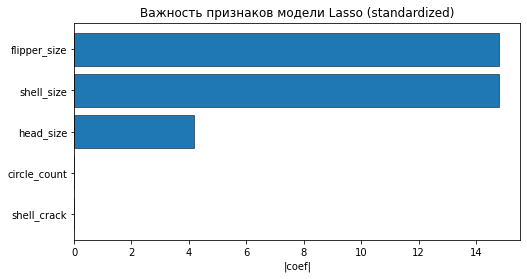

In [65]:
# Визуализация
plt.figure(figsize=(8, 4))
plt.barh(importance_df['feature'], importance_df['abs_coef'], edgecolor='black', linewidth=0.5)
plt.xlabel('|coef|')
plt.title('Важность признаков модели Lasso (standardized)')
plt.gca().invert_yaxis()  # самый важный признак сверху
plt.show()

Важность признака оцениваем по абсолютному значению коэффициента `coef_` - чем больше `|coef_|`, тем сильнее признак влияет на предсказание.

Лучшими по важности оказались два признака: `flipper_size` (`|coef|` = 14.81) и `shell_size` (`|coef|` = 14.81, практически идентично). Размер ласт и панциря вносят почти одинаковый и наибольший вклад в предсказание массы. `head_size` тоже значим, но заметно слабее (`|coef|` = 4.18) - примерно в 3.5 раза меньше двух лидеров.

`circle_count` и `shell_crack` L1-регуляризация обнулила полностью (`coef` = 0). `Lasso` посчитала их незначимыми для предсказания массы и фактически исключила из модели.

Согласен ли я с таким результатом? - Да, это физически логично: масса тела в первую очередь определяется общими габаритами (панцирь, ласты). Чем крупнее черепаха, тем она тяжелее, это прямая пропорция объёма/массы. `head_size` тоже растёт вместе с телом, но голова - относительно небольшая часть массы животного, поэтому её вклад ожидаемо слабее. 

Обнуление `circle_count` (кольца роста) и `shell_crack` (трещины панциря) тоже логично: они говорят о возрасте/состоянии панциря, но напрямую физическую массу через эти признаки не предсказать. Крупная старая черепаха и крупная молодая с одинаковым размером панциря будут весить примерно одинаково.

---

## Функция для прогнозирования веса черепахи

Напишем на Python функцию, которая будет прогнозировать массу черепахи по заданным параметрам с учётом коэффициентов лучшей модели (свойство `coef_`) и смещения (свойство `intercept_`).

In [66]:
# Параметры масштабирования, посчитанные ранее по обучающей выборке (train)
# Нужны, чтобы функция могла сама стандартизировать сырые данные так же, как при обучении
train_mean = X_train.mean(axis=0)
train_std = X_train.std(axis=0)

def predict_turtle_weight(shell_length, shell_width,
                           head_length, head_width,
                           flipper_length_1, flipper_width_1,
                           flipper_length_2, flipper_width_2,
                           flipper_length_3, flipper_width_3,
                           flipper_length_4, flipper_width_4,
                           circle_count, shell_crack,
                           model=best_model, mean=train_mean, std=train_std):
    """
    Прогнозирует массу черепахи (кг) по сырым (неагрегированным) измерениям TurtleCV.

    На вход подаются исходные габариты панциря, головы, четырёх ласт,
    а также circle_count и shell_crack - те же признаки, что были в исходном датасете.
    Функция сама агрегирует их (как на этапе устранения мультиколлинеарности),
    стандартизирует по параметрам обучающей выборки и применяет веса лучшей модели.
    """
    # Шаг 1. Агрегация признаков — та же логика, что и при построении df_mydas
    shell_size = np.mean([shell_length, shell_width])
    head_size = np.mean([head_length, head_width])
    flipper_size_1 = np.mean([flipper_length_1, flipper_width_1])
    flipper_size_2 = np.mean([flipper_length_2, flipper_width_2])
    flipper_size_3 = np.mean([flipper_length_3, flipper_width_3])
    flipper_size_4 = np.mean([flipper_length_4, flipper_width_4])
    flipper_size = np.mean([flipper_size_1, flipper_size_2, flipper_size_3, flipper_size_4])

    # Шаг 2. Собираем вектор признаков в том же порядке, что и при обучении модели
    # (circle_count, shell_crack, shell_size, head_size, flipper_size)
    x_raw = np.array([circle_count, shell_crack, shell_size, head_size, flipper_size])

    # Шаг 3. Стандартизация теми же mean/std, что использовались для X_train
    x_scaled = (x_raw - mean) / std

    # Шаг 4. Предсказание по формуле линейной модели: weight = coef_ @ x + intercept_
    weight_pred = np.dot(model.coef_, x_scaled) + model.intercept_

    return round(weight_pred, 3)


# Берём первую строку сырых данных (до агрегации) для проверки
row = df_mydas_befor_agr.iloc[0]

predicted = predict_turtle_weight(
    shell_length=row['shell_length'], shell_width=row['shell_width'],
    head_length=row['head_length'], head_width=row['head_width'],
    flipper_length_1=row['flipper_length_1'], flipper_width_1=row['flipper_width_1'],
    flipper_length_2=row['flipper_length_2'], flipper_width_2=row['flipper_width_2'],
    flipper_length_3=row['flipper_length_3'], flipper_width_3=row['flipper_width_3'],
    flipper_length_4=row['flipper_length_4'], flipper_width_4=row['flipper_width_4'],
    circle_count=row['circle_count'], shell_crack=row['shell_crack']
)

print(f'Предсказанная масса: {predicted} кг')
print(f'Реальная масса: {row["weight"]} кг')

Предсказанная масса: 54.568 кг
Реальная масса: 56.352 кг


Расхождение всего 1.784 кг (реальная 56.352 против предсказанной 54.568), это меньше нашего среднего MAE (~4 кг на тесте), то есть функция работает корректно и результат вполне в рамках ожидаемой точности модели.

## Общие выводы и рекомендации по дальнейшей работе

Напишем общие выводы и рекомендации по дальнейшей работе.
  - **Какие модели изучены**. В рамках проекта построено и сравнено 4 архитектуры линейных моделей: `LinearRegression` (без регуляризации), `Lasso` (L1-регуляризация), `Ridge` (L2-регуляризация) и `SGDRegressor` (градиентный спуск, протестирован с тремя функциями потерь: `squared_error`, `huber`, `epsilon_insensitive`). Каждая модель обучена на трёх вариантах масштабирования признаков (без масштабирования, нормализация, стандартизация). Итого рассмотрено более 15 комбинаций модель+датасет. В качестве базовой точки отсчёта использован `DummyRegressor`. 
  - **Какие результаты получены.** Масштабирование признаков оказалось критически важным фактором: `SGDRegressor` без масштабирования полностью потерял устойчивость (веса порядка 10¹¹), тогда как на стандартизированных и нормализованных данных все модели показали близкое качество (`MAE` 4.0–4.1 кг, `R²` ~0.97 на валидации). Все линейные модели уверенно превзошли базовую (`DummyRegressor`: `MAE` ~29.6 кг, `R²` ~0). Улучшение `MAE` составило 80–87%.
  - **Рекомендуется ли итоговая модель к внедрению?** Да. Лучшая модель - `Lasso` на стандартизированных признаках. На тестовой выборке она показала `MAE` = 4.071 кг (< 5 кг, критерий заказчика выполнен) и `R²` = 0.9712 (≥ 0.97, критерий выполнен). Признаков переобучения не обнаружено: метрики на `test` не хуже, а местами лучше, чем на `val`, что говорит о хорошей обобщающей способности модели.
  - **Какая архитектура и способ обработки признаков показали себя лучше всего? Какие у них показатели метрик?** - `Lasso` (L1-регуляризация) на стандартизированных признаках. Финальные метрики на тестовой выборке: `MAE` = 4.071 кг, `MSE` = 35.774, `R²` = 0.9712, `MAPE` = 4.258%.
  - **Какие признаки наиболее важны для модели?** - По абсолютному значению весов лучшей модели наиболее значимы `flipper_size` и `shell_size` (практически равный вклад, `|coef|` ~14.8) - размер ласт и панциря. `head_size` значим слабее (`|coef|` = 4.18). `circle_count` и `shell_crack` L1-регуляризация обнулила полностью. Они оказались избыточны для предсказания массы, что физически логично: это индикаторы возраста/состояния панциря, а не прямые габариты тела.
  - **Есть ли перспективы у обучения этой или других моделей для предсказания массы других видов черепах?** - Да, подход в целом переносим: пайплайн (агрегация габаритов -> устранение мультиколлинеарности -> масштабирование -> линейная регрессия с регуляризацией) не завязан специфично на `Chelonia mydas`.
  - **Предложения по дальнейшему развитию проекта:** 
    - Проверить нелинейные модели